# Lab: Visualizing Text Data

Select **two distinct text datasets**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of figures for each question**, for a total of two research questions and four figures.

Each pair of figures should provide complementary evidence about the text. You may use Seaborn, Matplotlib, Plotly Express, or WordCloud. Choose datasets whose language is **work appropriate**.


## Learning goals

- Select and document usable text datasets.
- Ask focused questions about vocabulary, text length, or differences between groups.
- Prepare text reproducibly while preserving original wording for context checks.
- Choose and interpret two complementary figures per question.
- Distinguish word occurrences from the number or percentage of documents containing a word.
- Support conclusions with checked evidence and explain the limitations of the data and displays.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.


## Select your two datasets

Each dataset needs:

- A documented source and definitions for the features you use.
- Actual text, such as headlines, posts, descriptions, reviews, or passages—not only ratings or precomputed sentiment scores.
- Enough separate documents or passages to support your question. Define what one row represents.
- Relevant group labels if you plan to compare categories, authors, sources, or ratings. Document any groups you create.

Use two distinct datasets, not two filters of the same collection. A comparison of two categories from one collection counts as **one dataset and one investigation**. Choose your own questions rather than repeating the SMS lecture. Other documented sources are welcome.

Choose a manageable subset before analysis and document any sampling and its random seed. Save fixed copies in this notebook's `data` folder and use relative paths. Preserve the original text alongside prepared features. If you assemble passages from books, document their boundaries and retain book and author identifiers; passages from one book are not independent samples of all literature.

### Work-appropriate language

Be mindful that your datasets should be **work appropriate** for a classroom presentation. Read sample records and review the words, excerpts, and hover text that your figures will display. Public availability does not guarantee appropriate content. Choose another source or document any content-based exclusions when needed; explain how screening may affect your results. Review the final outputs before submitting. The suggestions below have not been screened for you.


### Candidate datasets

| Candidate and source | Useful text and grouping information | Possible question and figure pair |
| --- | --- | --- |
| [UCI News Aggregator](https://archive.ics.uci.edu/dataset/359/news+aggregator) | News titles, category, publisher, and story identifiers. Use `newsCorpora.csv` and its README; analyze titles rather than assuming the file contains full articles. Start with two categories and a manageable sample. | How does vocabulary differ between business and science/technology headlines? Use a word-frequency bar chart and a word-frequency scatter plot. Repeated coverage of the same story may affect counts. |
| [20 Newsgroups through scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html) | Posts and topic labels. Consider `rec.sport.baseball` and `sci.space`. The loader supports selecting categories and removing headers, footers, and quoted replies. Save the selected text and labels locally. | How do vocabulary and post length differ between baseball and space discussions? Use grouped word-frequency bars and a text-length box plot. Screen the posts; topic selection does not guarantee clean language. |
| [Project Gutenberg](https://www.gutenberg.org/) | Downloadable books with author and title information. Assemble a collection of clearly defined passages or chapters from selected books and preserve their source identifiers. Remove book headers and license boilerplate from the analysis copy. | Which words characterize selected adventure and nature-writing books? Use word clouds and a grouped word-frequency chart. Multiple books per group support a broader comparison than one book per group. |

Adapt the question to the available fields. A second pair of categories from the same collection does not satisfy the second-dataset requirement. The questions and chart pairs are starting points, not required choices.


## Choose two complementary figures per question

Choose **different chart types**, not two versions differing only in color, title, selected words, or counts versus percentages. You may reuse a chart type for the second dataset. A group of word clouds counts as one figure type; it cannot supply both figures by itself. At least one figure per question must support a numerical comparison, such as a bar chart, scatter plot, box plot, or heatmap.

| Figure | Tools | What it can help you see |
| --- | --- | --- |
| Word cloud | `WordCloud` and Matplotlib | An initial impression of prominent vocabulary. Each cloud scales its own words; font sizes are not precise comparisons across clouds. |
| Word-frequency bar chart | `sns.barplot()` or `px.bar()` | Exact occurrences or the percentage of documents containing selected words. State the denominator and use the same word selection across groups. |
| Word-frequency scatter plot | `px.scatter()` | Each point is a word, with its document percentage in group A on x and group B on y. Use equal scales and an equal-percentage reference line. |
| Text-length box plot or histogram | `sns.boxplot()`, `sns.histplot()`, `px.box()`, or `px.histogram()` | How document lengths vary within or across groups. Define length in words or characters. Length alone does not measure sentiment or quality. |
| Word-by-group heatmap—an additional option | `sns.heatmap()` or `px.imshow()` | How the percentage of documents containing a word varies across several groups. Use one common color scale and state its units. |

Keep different measures in separate figures. Explain how each figure helps answer the same research question. A plot of group sizes is useful context, but it cannot replace a required text-analysis figure unless it directly answers your question about the text.


### Preparation and interpretation guidance

- Preserve an original-text column and a document identifier. Decide how to handle blank text, duplicates, URLs, punctuation, case, and boilerplate.
- Start with scikit-learn's `ENGLISH_STOP_WORDS` for English text, then use an editable `additional_stopwords` list as in the lecture. Justify additions and apply the same choices to compared groups. Other languages need appropriate preparation.
- Report how many documents are in each group. Unequal numbers of documents and different document lengths affect raw word counts.
- **Word occurrences** count every repetition. **Percent of documents containing a word** counts each document once, divided by all documents in that group, including documents without the word. This is not the percentage of a word's matches that belong to a group.
- Define and document any display threshold or top-word selection. A word absent from the displayed chart is not necessarily absent from the data.
- Use descriptive titles, readable labels, common scales for common measures, and useful hover information where applicable. Keep counts and percentages on separate figures.
- Reuse or adapt the lecture's preparation and sample-message function, explaining your changes. No classifier, sentiment model, or train/test split is required.


### Starting pattern for an additional chart type

This is an **adaptation example**, not code to run unchanged. It assumes `tokens_df` has one row per retained word occurrence, with `document_id`, `group`, and `word`, and `documents_df` has one row per document. Replace these names with yours.

```python
# Count each document once per word, even if the word repeats.
word_counts = tokens_df.groupby(['group', 'word'])['document_id'].nunique().reset_index(name='documents_with_word')
group_sizes = documents_df.groupby('group')['document_id'].nunique()
word_counts['percent_documents'] = 100 * word_counts['documents_with_word'] / word_counts['group'].map(group_sizes)

# Show the ten words occurring in the most documents overall.
selected_words = tokens_df.groupby('word')['document_id'].nunique().nlargest(10).index
grid = word_counts.pivot(index='word', columns='group', values='percent_documents')
grid = grid.reindex(index=selected_words, columns=group_sizes.index).fillna(0)
sns.heatmap(grid, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': 'Percent of documents in each group containing the word'})
plt.xlabel('Group')
plt.ylabel('Word')
plt.title('Selected vocabulary across groups')
plt.show()
```

Use unique document IDs across the collection. Here zero means no retained occurrence was observed in a group with documents; it does not replace missing source text. Choose a manageable number of words and groups so labels remain readable.


In [1]:
%matplotlib inline
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from IPython.display import display

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

def fixed_lcg_sample(frame, n, seed):
    """Stable Fisher-Yates subsample; seeded 32-bit LCG for an exact saved snapshot."""
    positions = list(range(len(frame)))
    state = seed
    for i in range(len(positions) - 1, 0, -1):
        state = (1664525 * state + 1013904223) % (2**32)
        j = state % (i + 1)
        positions[i], positions[j] = positions[j], positions[i]
    return frame.iloc[positions[:n]].copy()

def words_in(text, extra_stopwords=()):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    tokens = re.findall(r"[a-z']+", text)
    stop = set(ENGLISH_STOP_WORDS) | set(extra_stopwords)
    return [token for token in tokens if len(token) >= 3 and token not in stop]

def context_samples(frame, word, text_col, id_col, group_col="group", count=2):
    """Short original-text excerpts for checking whether a word reflects the apparent topic."""
    pat = re.compile(r"\b" + re.escape(word) + r"\b", flags=re.I)
    for group, part in frame.groupby(group_col):
        hits = part.loc[part[text_col].fillna("").str.contains(pat)]
        print(f"\n{group}: {len(hits)} documents contain '{word}'")
        for row in hits.head(count).itertuples(index=False):
            record = row._asdict()
            raw = " ".join(str(record[text_col]).split())
            match = pat.search(raw)
            excerpt = raw[max(0, match.start() - 65):match.end() + 95] if match else raw[:130]
            print(f"  ID {record[id_col]}: ...{excerpt}...")
print("Analysis setup complete. Sampling seeds: 42, 43, 44, 45.")


Analysis setup complete. Sampling seeds: 42, 43, 44, 45.


## Investigation 1: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

My research question is: How does the vocabulary in high-rated (4-5 stars) versus low-rated (1-2 stars) Universal Orlando reviews differ, and are low-rated reviews longer? I predict more positive terms such as "great" and "fun" in high ratings, more waiting-related or disappointment terms in low ratings, and longer low-rated reviews. Text analysis can compare the percentage of reviews containing a given word and summarize original review lengths rather than assuming every review of a rating says the same thing.


### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Dataset: **Universal Orlando historical reviews sample**, supplied by the Data Visualization and Modeling course repository. Course publisher: the course repository; the underlying original review website/publisher is not identified in the CSV, so I do not claim one. Direct fixed source: [universal_orlando_reviews_sample.csv](https://github.com/FlameBorneWhiteHat-FB-91156/Data_Visualization_and_Modeling_Campus/blob/main/week04/lab/data/universal_orlando_reviews_sample.csv). Feature definitions are the CSV headers: review_id (record identifier), rating (1-5 stars), review_text (original review), and review_date (date). Accessed 2026-11-22. Saved analysis snapshot: `data/universal_review_analysis_subset.csv`, sampling seeds 42 and 43. The original course file remains in `data/`.


**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

One source row is one historical review, not one visitor. The source contains 3,000 reviews dated 2004-02-17 through 2021-05-15, including references to both Universal Studios and Islands of Adventure, so it is not a clean measure of one attraction. The two research groups are 4-5 stars (2,449 eligible reviews) and 1-2 stars (273 eligible reviews); 3-star reviews are excluded from this contrast. The sampled 320 records were checked for blank text, duplicate text, and a limited list of stronger language terms; no sampled texts triggered that screen. I examined source excerpts before using them in interpretations. Screening is imperfect and public review text may still contain unsuitable language.


In [2]:
# Load the supplied historical review collection, then save an exact, balanced subset.
review_file = DATA_DIR / "universal_orlando_reviews_sample.csv"
if not review_file.is_file():
    repo_file = Path("week04/lab/data/universal_orlando_reviews_sample.csv")
    if repo_file.is_file():
        review_file = repo_file
    else:
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        source_url = "https://raw.githubusercontent.com/FlameBorneWhiteHat-FB-91156/Data_Visualization_and_Modeling_Campus/main/week04/lab/data/universal_orlando_reviews_sample.csv"
        try:
            pd.read_csv(source_url).to_csv(review_file, index=False)
        except Exception as error:
            raise FileNotFoundError(
                "Universal reviews CSV is not available in this JupyterLab workspace. "
                "Open the notebook from week04/lab or place the CSV in its data folder."
            ) from error
review_source_df = pd.read_csv(review_file)
high_source_df = review_source_df.loc[review_source_df["rating"] >= 4]
low_source_df = review_source_df.loc[review_source_df["rating"] <= 2]
high_review_df = fixed_lcg_sample(high_source_df, 160, 42).assign(group="High (4-5)")
low_review_df = fixed_lcg_sample(low_source_df, 160, 43).assign(group="Low (1-2)")
review_selected_df = pd.concat([high_review_df, low_review_df], ignore_index=True).sort_values("review_id").reset_index(drop=True)
review_selected_df.to_csv(DATA_DIR / "universal_review_analysis_subset.csv", index=False)
print(f"Original records: {len(review_source_df)}; high-rated available: {len(high_source_df)}; low-rated available: {len(low_source_df)}")
print(f"Snapshot: {len(review_selected_df)} documents; {review_selected_df['group'].value_counts().to_dict()}")


Original records: 3000; high-rated available: 2449; low-rated available: 273
Snapshot: 320 documents; {'Low (1-2)': 160, 'High (4-5)': 160}


In [3]:
display(review_source_df.head())

,review_id,rating,review_text,review_date
0,1,5.0,"If you visit Orlando, you have to take two day...",2004-02-17
1,2,5.0,"My family of 5 ( 2 adults, 3 kids(17,17,+3) ha...",2004-07-06
2,3,1.0,Went to universal this september. What a waste...,2004-10-25
3,4,5.0,I think these parks (Universal Studios and Isl...,2005-01-03
4,5,1.0,"3 hours to get on a ride, $5 icees and $7 for ...",2005-03-31


In [4]:
display(review_source_df.tail())


,review_id,rating,review_text,review_date
2995,2996,1.0,TLDR; They don’t observe or enforce Covid safe...,2021-04-28
2996,2997,1.0,I've been waiting multiple DAYS on the phone t...,2021-05-04
2997,2998,1.0,✅ $850💵 + ⏰ hours of high heat 91 degrees🔥 & 😷...,2021-05-04
2998,2999,3.0,My husband and I visited Universal a couple ye...,2021-05-06
2999,3000,5.0,Harry Potter world was especially awesome and ...,2021-05-15


In [5]:
print('Review source shape:', review_source_df.shape)


Review source shape: (3000, 4)


In [6]:
review_source_df.info()
print("Missing source values by column:", review_source_df.isna().sum().to_dict())
print("Blank source review texts:", review_source_df["review_text"].fillna("").str.strip().eq("").sum())
print("Missing selected values:", review_selected_df.isna().sum().to_dict())
print("Blank selected texts:", review_selected_df["review_text"].fillna("").str.strip().eq("").sum())
print("Duplicate selected review IDs:", review_selected_df["review_id"].duplicated().sum())
print("Duplicate selected texts:", review_selected_df["review_text"].duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   review_id    3000 non-null   int64  
 1   rating       3000 non-null   float64
 2   review_text  3000 non-null   object 
 3   review_date  3000 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 93.9+ KB
Missing source values by column: {'review_id': 0, 'rating': 0, 'review_text': 0, 'review_date': 0}
Blank source review texts: 0
Missing selected values: {'review_id': 0, 'rating': 0, 'review_text': 0, 'review_date': 0, 'group': 0}
Blank selected texts: 0
Duplicate selected review IDs: 0
Duplicate selected texts: 0


**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

Use text, quantitative, categorical, or temporal for feature type.

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values in 320 selected reviews |
| --- | --- | --- | --- | --- |
| review_id | Unique review record identifier | Categorical (identifier) | int64 | 0 |
| rating | Original rating, 1 to 5 stars | Quantitative | float64 | 0 |
| review_date | Date associated with review | Temporal | object (date string) | 0 |
| review_text | Original review wording | Text | object | 0 |
| group | Derived High (4-5) or Low (1-2) | Categorical | object | 0 |
| length_words | Count of whitespace-separated words | Quantitative | int64 | 0 |
| tokens | Prepared words retained for charts | Text (list of words) | object | 0 |


**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

I used a fixed, balanced subset of 160 high-rated and 160 low-rated reviews. I applied a reproducible Fisher-Yates selection using a 32-bit linear congruential generator with seeds 42 (high) and 43 (low), and saved the exact selected original records. The source had no missing or blank review text; the selected subset has none and no duplicated review IDs or exact review texts. I retained the original wording and review identifiers, counted review length using whitespace-separated words, lowercased and extracted alphabetic words, removed the scikit-learn English stopwords, and removed "universal", "orlando", and "studios" only from frequency displays because they identify the setting rather than the experience. I kept words such as "rides", "wait", "great", and "staff". I did not use a sentiment model. Automated language screening found no sampled review containing the specified stronger-language terms.


In [7]:
review_stopwords_extra = {"universal", "orlando", "studios"}
review_selected_df["length_words"] = review_selected_df["review_text"].str.split().str.len()
review_selected_df["tokens"] = review_selected_df["review_text"].map(lambda s: words_in(s, review_stopwords_extra))
review_tokens_df = review_selected_df[["review_id", "group", "tokens"]].explode("tokens").rename(columns={"tokens": "word"})
review_tokens_df = review_tokens_df.dropna(subset=["word"]).copy()
review_group_sizes = review_selected_df.groupby("group")["review_id"].nunique()
review_freq_df = (review_tokens_df.groupby(["group", "word"])
                  .agg(occurrences=("word", "size"), documents_with_word=("review_id", "nunique")).reset_index())
review_freq_df["percent_documents"] = 100 * review_freq_df["documents_with_word"] / review_freq_df["group"].map(review_group_sizes)
print("Review lengths by group:")
print(review_selected_df.groupby("group")["length_words"].agg(["count", "mean", "median", "min", "max"]).round(2))
print("Retained documents:", len(review_selected_df), "; retained token occurrences:", len(review_tokens_df))


Review lengths by group:
            count    mean  median  min   max
group                                       
High (4-5)    160  106.83    68.5   14   963
Low (1-2)     160  199.19   124.5   15  2253
Retained documents: 320 ; retained token occurrences: 20496


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

The original dataset has 3,000 rows. The analysis subset retains 320 reviews (160 per rating group), leaving out 2,680 source rows through group selection and fixed sampling; no selected rows were removed for blank text, exact duplicates, or screening. Each row of review_selected_df is one review, while each row of review_tokens_df is one retained word occurrence from a particular review. A review may contribute many word occurrences but counts only once in a document-percentage measure.


### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Figure 1 is a two-panel word cloud showing high-rated and low-rated vocabulary. Word size within a cloud represents retained word occurrences; colors only distinguish panels, and font size should not be compared across independently scaled clouds. Figure 2 is a grouped horizontal bar chart of selected words. Bar length represents the percent of reviews containing a word at least once, calculated separately as 100 * unique reviews containing the word / 160 reviews in that rating group. I also summarize original review lengths using the median and mean number of whitespace-separated words, without treating length as sentiment.


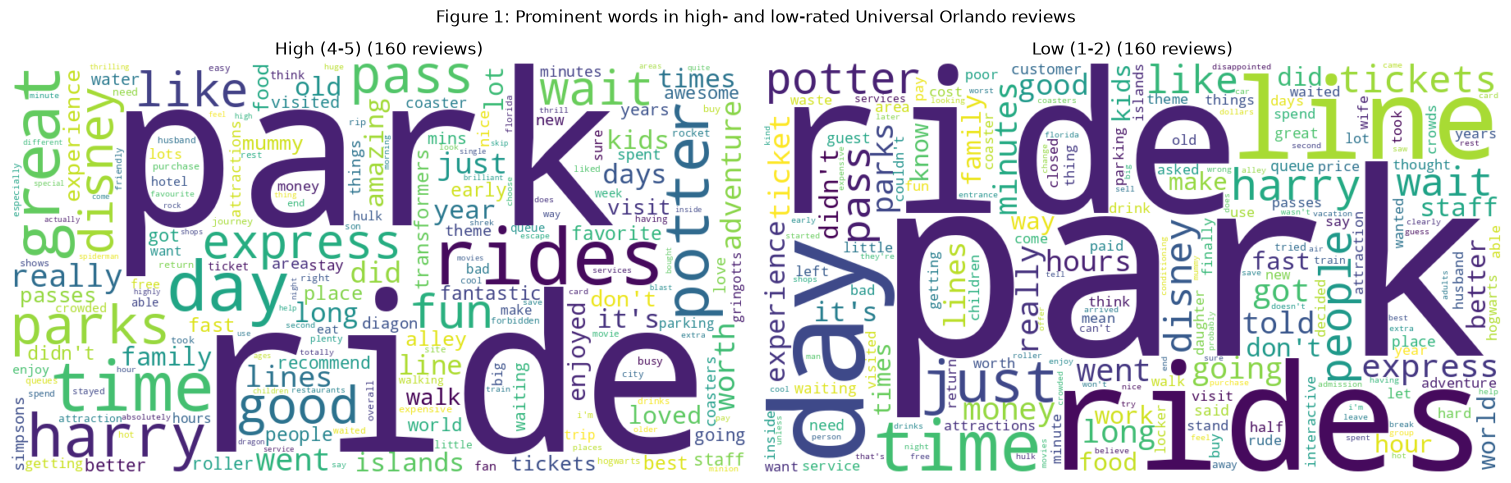

In [8]:
# Figure 1: Two word clouds are one figure type; each panel scales independently.
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, group in zip(axes, ["High (4-5)", "Low (1-2)"]):
    term_counts = review_freq_df.loc[review_freq_df["group"].eq(group)].set_index("word")["occurrences"]
    cloud = WordCloud(width=900, height=500, background_color="white", collocations=False,
                      random_state=42).generate_from_frequencies(term_counts.to_dict())
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(group + " (160 reviews)")
    ax.axis("off")
fig.suptitle("Figure 1: Prominent words in high- and low-rated Universal Orlando reviews")
plt.savefig(FIG_DIR / "review_wordcloud.png", dpi=170, bbox_inches="tight")
plt.show()


**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Figure 1 gives a quick view of recurring vocabulary in both rating groups. For example, "rides" occurs 137 times in the 160 high-rated reviews and 172 times in the 160 low-rated reviews, including repetitions within a review. This shows that the topic of rides appears in both positive and negative reviews, but a cloud alone cannot say whether mentions of rides are positive or negative. Because each cloud scales independently, I do not infer that a word shown in a larger font in one panel is necessarily more frequent than in the other panel.


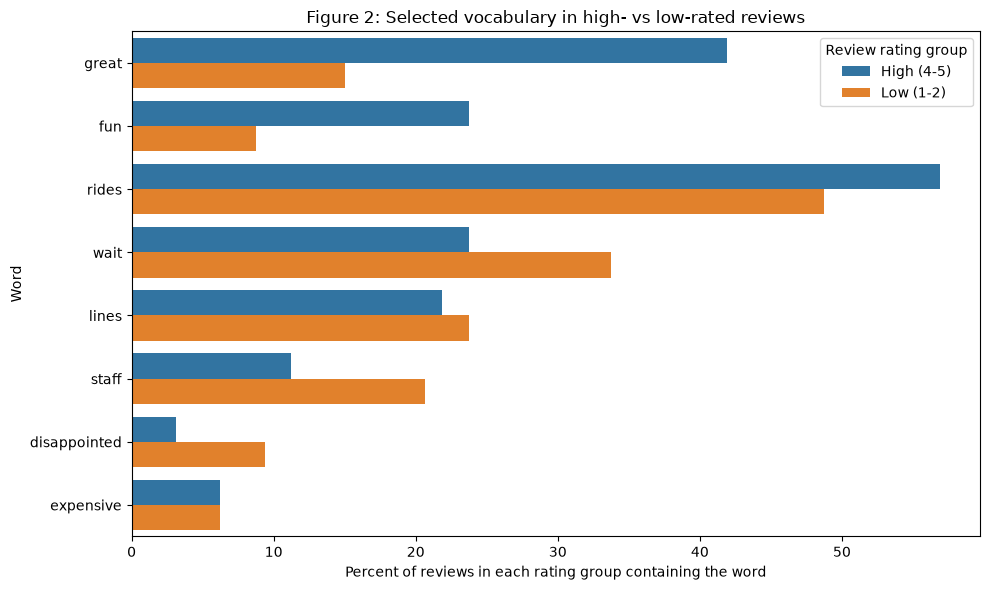

In [9]:
# Figure 2: Within-group document percentages, rather than raw occurrences.
review_selected_words = ["great", "fun", "rides", "wait", "lines", "staff", "disappointed", "expensive"]
review_group_order = ["High (4-5)", "Low (1-2)"]
review_chart_df = (review_freq_df.set_index(["group", "word"])
                   .reindex(pd.MultiIndex.from_product([review_group_order, review_selected_words], names=["group", "word"]),
                            fill_value=0).reset_index())
plt.figure(figsize=(10, 6))
sns.barplot(data=review_chart_df, y="word", x="percent_documents", hue="group",
            order=review_selected_words, hue_order=review_group_order)
plt.xlabel("Percent of reviews in each rating group containing the word")
plt.ylabel("Word")
plt.title("Figure 2: Selected vocabulary in high- vs low-rated reviews")
plt.legend(title="Review rating group")
plt.tight_layout()
plt.savefig(FIG_DIR / "review_word_percent.png", dpi=170)
plt.show()


**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Figure 2 provides a numerical comparison that the clouds cannot. "Great" appears in 67 of 160 high-rated reviews (41.88%) but 24 of 160 low-rated reviews (15.00%). "Wait" appears in 38 of 160 high-rated reviews (23.75%) versus 54 of 160 low-rated reviews (33.75%), and "disappointed" appears in 5 high-rated reviews (3.13%) versus 15 low-rated reviews (9.38%). Low-rated reviews also have a larger median original length, 124.5 words versus 68.5 for high-rated reviews, and a larger mean, 199.19 versus 106.83 words. Percentages use all 160 reviews in the relevant group as the denominator.


### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [10]:
# Independently verify specific values and inspect how the original words were used.
for group, word, expected in [("High (4-5)", "great", 67), ("Low (1-2)", "great", 24),
                              ("High (4-5)", "wait", 38), ("Low (1-2)", "wait", 54)]:
    rows = review_selected_df.loc[review_selected_df["group"] == group]
    count = rows["review_text"].str.lower().str.findall(r"[a-z']+").map(lambda v: word in v).sum()
    print(f"{group}: {word} = {count}/{len(rows)} ({100 * count / len(rows):.2f}%)")
    assert count == expected, "A plotted review count does not match source records."
context_samples(review_selected_df, "wait", "review_text", "review_id")


High (4-5): great = 67/160 (41.88%)
Low (1-2): great = 24/160 (15.00%)
High (4-5): wait = 38/160 (23.75%)
Low (1-2): wait = 54/160 (33.75%)

High (4-5): 38 documents contain 'wait'
  ID 74: ...kip the line on. It was an amazing ride and well worth the short wait that early in the morning. Later in the evening we went back to do it again and wait over two ...
  ID 95: ... Harry Potter. It was nice because it wasnt crowded and the most wait time was15 minutes. I liked the way the rides were set up because as hot as it was outside we ...

Low (1-2): 54 documents contain 'wait'
  ID 21: ...ers walked up and walked in ahead of us. This of course made our wait longer. We started off with the Men in Black ride, which involved using play laser guns to sho...
  ID 23: ...le waiting in line who just flat out refused to move. The posted wait time when we entered the line was 60 minutes. 104 minutes later we got on the ride. The park j...


**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

I checked four underlying counts against the original selected review texts: "great" occurs in 67 high-rated and 24 low-rated reviews, and "wait" occurs in 38 high-rated and 54 low-rated reviews. These agreed with the Figure 2 group-percentage calculations. Looking at original "wait" excerpts showed that a high-rated reviewer can say "cannot wait to return", while low-rated reviews may complain about queues or long waits. The word alone does not prove a negative experience; interpretation requires context. No correction to the computed counts was needed.


### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

My research question asked how high- and low-rated Universal Orlando reviews differ in word choice and length. The visualizations support the prediction that positive language is more common in high ratings and some complaint-related vocabulary is more common in low ratings: 41.88% of high-rated reviews contain "great", compared with 15.00% of low-rated reviews, while "wait" appears in 23.75% versus 33.75%, respectively. The paired word clouds provide context about prominent terms, while the normalized bar chart makes percentages comparable across groups. Low-rated reviews are also longer in this selected sample, with a median of 124.5 words versus 68.5 words for high-rated reviews. These findings describe the sampled reviews, not all park visitors.


### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

First, these are self-selected, historical online reviews covering multiple Universal Orlando attractions; a balanced 160/160 subset does not estimate the real proportion of satisfied and dissatisfied visitors. Second, simple word counts ignore context, sarcasm, negation, and changing meanings over time. The word clouds make recurring vocabulary easy to notice but scale each panel independently and cannot support precise cross-panel comparisons. The document-percentage bars support precise comparisons, but a word's presence cannot tell us whether the reviewer liked the thing mentioned. Review length is an additional quantitative descriptor, not a measure of satisfaction or quality.


## Investigation 2: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

My research question is: How do injury-related words and narrative lengths differ between bicycle and scooter emergency-department incident records for ages 5-17 in the course's prepared 2025 CPSC NEISS dataset? I predict that both groups will frequently mention falls, while terms such as "helmet" and "head" may differ in frequency and the narrative lengths may be similar. Comparing documented words and word counts can show recording patterns without incorrectly treating the sample as a national injury-rate estimate.


### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Dataset: **CPSC NEISS 2025 school-age micromobility case narratives**, a prepared course copy derived from the U.S. Consumer Product Safety Commission National Electronic Injury Surveillance System. Publisher: U.S. CPSC; the course repository prepared the device categories. Official data documentation: [CPSC NEISS](https://www.cpsc.gov/Research--Statistics/NEISS-Injury-Data). Fixed source in this repository: [cpsc_neiss_school_age_micromobility_2025.csv](https://github.com/FlameBorneWhiteHat-FB-91156/Data_Visualization_and_Modeling_Campus/blob/main/week04/lecture/data/cpsc_neiss_school_age_micromobility_2025.csv). Feature details: [course data README](https://github.com/FlameBorneWhiteHat-FB-91156/Data_Visualization_and_Modeling_Campus/blob/main/dashboards/class-demo/data/README.md). Accessed 2026-11-22. Saved analysis snapshot: `data/neiss_micromobility_analysis_subset.csv`, seeds 44 and 45.


**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

One source row represents one **unweighted emergency-department case record** rather than one rider, trip, or national injury. The prepared dataset contains 6,212 cases for ages 5-17, with 4,747 bicycle-family and 1,465 scooter-family records. The course data preparation excluded 97 overlapping-device records. Device family is a supplied category; the scooter family includes powered and unpowered scooters, and powered does not necessarily mean electric. I inspected representative original narratives and screened the chosen sample for blank or duplicate text and stronger inappropriate words; no sampled case triggered the limited text screen. These are short clinical narratives; some mention injuries, so I used brief contextual excerpts and neutral medical terms rather than sensational text.


In [11]:
# CPSC NEISS narratives are independent of the Universal Orlando review collection.
cpsc_name = "cpsc_neiss_school_age_micromobility_2025.csv"
cpsc_file = Path("../lecture/data") / cpsc_name
if not cpsc_file.is_file():
    repo_file = Path("week04/lecture/data") / cpsc_name
    local_file = DATA_DIR / cpsc_name
    if repo_file.is_file():
        cpsc_file = repo_file
    elif local_file.is_file():
        cpsc_file = local_file
    else:
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        source_url = "https://raw.githubusercontent.com/FlameBorneWhiteHat-FB-91156/Data_Visualization_and_Modeling_Campus/main/week04/lecture/data/" + cpsc_name
        try:
            pd.read_csv(source_url).to_csv(local_file, index=False)
            cpsc_file = local_file
        except Exception as error:
            raise FileNotFoundError(
                "NEISS CSV is not available in this JupyterLab workspace. "
                "Open from week04/lab or place the source CSV in the notebook data folder."
            ) from error
cpsc_source_df = pd.read_csv(cpsc_file)
bike_source_df = cpsc_source_df.loc[cpsc_source_df["device_family"].eq("Bicycles")]
scooter_source_df = cpsc_source_df.loc[cpsc_source_df["device_family"].eq("Scooters")]
bike_selected_df = fixed_lcg_sample(bike_source_df, 200, 44).assign(group="Bicycles")
scooter_selected_df = fixed_lcg_sample(scooter_source_df, 200, 45).assign(group="Scooters")
cpsc_selected_df = pd.concat([bike_selected_df, scooter_selected_df], ignore_index=True).sort_values("case_number").reset_index(drop=True)
cpsc_selected_df = cpsc_selected_df[["case_number", "device_family", "device_type", "narrative", "group"]]
cpsc_selected_df.to_csv(DATA_DIR / "neiss_micromobility_analysis_subset.csv", index=False)
print(f"Original CPSC cases: {len(cpsc_source_df)}; bicycles available: {len(bike_source_df)}; scooters available: {len(scooter_source_df)}")
print(f"Snapshot: {len(cpsc_selected_df)} cases; {cpsc_selected_df['group'].value_counts().to_dict()}")


Original CPSC cases: 6212; bicycles available: 4747; scooters available: 1465
Snapshot: 400 cases; {'Scooters': 200, 'Bicycles': 200}


In [12]:
display(cpsc_source_df.head())

,case_number,treatment_date,age,sex,race,body_part,diagnosis,disposition,device_type,device_family,month,additional_care,narrative
0,250105698,2025-01-02,10,Male,Black/African American,Hand,"Contusions, abrasion",Treated/Examined And Released,Non-electric bicycle,Bicycles,January,False,10 YOM C/O HAND ABRASION S/P BIKE CRASH. DX: H...
1,250107082,2025-01-01,16,Male,White,Hand,Fracture,Treated/Examined And Released,Non-electric bicycle,Bicycles,January,False,"16YOM, PRESENTING WITH LEFT HAND PAIN SINCE FA..."
2,250108280,2025-01-02,10,Male,Black/African American,Foot,"Contusions, abrasion",Treated/Examined And Released,Powered scooter,Scooters,January,False,10YOM RIDING AN ELECTRIC SCOOTER AND HIT BY A ...
3,250111300,2025-01-02,8,Female,Black/African American,Head,Other,Treated/Examined And Released,Powered scooter,Scooters,January,False,8 YOF C/O HEAD AND CHEST PAIN AFTER FALLING OF...
4,250114421,2025-01-04,7,Male,White,Head,Internal Injury,Treated/Examined And Released,Non-electric bicycle,Bicycles,January,False,7 YOM FELL OFF HIS BIKE AT A LOW RATE OF SPEED...


In [13]:
display(cpsc_source_df.tail())


,case_number,treatment_date,age,sex,race,body_part,diagnosis,disposition,device_type,device_family,month,additional_care,narrative
6207,260214706,2025-12-25,10,Female,White,Lower Trunk,Laceration,Treated/Examined And Released,Powered scooter,Scooters,December,False,10YOF FELL OFF E-SCOOTER AND NOW HAS ABRASION ...
6208,260215429,2025-12-27,17,Male,Other,Face,"Contusions, abrasion",Treated/Examined And Released,Powered scooter,Scooters,December,False,17YOM FELT HIS E-SCOOTER WOBBLING AND FELL FOR...
6209,260215430,2025-12-27,13,Male,Other,Knee,Laceration,Treated/Examined And Released,Powered scooter,Scooters,December,False,13YOM FELL FROM ELECTRIC SCOOTER AND LANDED ON...
6210,260216270,2025-12-29,13,Male,White,Head,Concussion,Treated/Examined And Released,Powered scooter,Scooters,December,False,13YOM WAS RIDING AN ELECTRIC SCOOTER WHEN HE L...
6211,260216276,2025-12-29,13,Male,Black/African American,Lower Arm,Fracture,Treated/Examined And Released,E-bike,Bicycles,December,False,13YOM WAS RIDING AN EBIKE WHEN HE FELL OVER HA...


In [14]:
print('CPSC source shape:', cpsc_source_df.shape)


CPSC source shape: (6212, 13)


In [15]:
cpsc_source_df.info()
print("Missing source values by column:", cpsc_source_df.isna().sum().to_dict())
print("Blank source narratives:", cpsc_source_df["narrative"].fillna("").str.strip().eq("").sum())
print("Missing selected values:", cpsc_selected_df.isna().sum().to_dict())
print("Blank selected narratives:", cpsc_selected_df["narrative"].fillna("").str.strip().eq("").sum())
print("Duplicate selected case numbers:", cpsc_selected_df["case_number"].duplicated().sum())
print("Duplicate selected texts:", cpsc_selected_df["narrative"].duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6212 entries, 0 to 6211
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   case_number      6212 non-null   int64 
 1   treatment_date   6212 non-null   object
 2   age              6212 non-null   int64 
 3   sex              6212 non-null   object
 4   race             6212 non-null   object
 5   body_part        6212 non-null   object
 6   diagnosis        6212 non-null   object
 7   disposition      6212 non-null   object
 8   device_type      6212 non-null   object
 9   device_family    6212 non-null   object
 10  month            6212 non-null   object
 11  additional_care  6212 non-null   bool  
 12  narrative        6212 non-null   object
dtypes: bool(1), int64(2), object(10)
memory usage: 588.6+ KB
Missing source values by column: {'case_number': 0, 'treatment_date': 0, 'age': 0, 'sex': 0, 'race': 0, 'body_part': 0, 'diagnosis': 0, 'disposition': 0, 'd

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

Use text, quantitative, categorical, or temporal for feature type.

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values in 400 selected cases |
| --- | --- | --- | --- | --- |
| case_number | Unique CPSC case record identifier | Categorical (identifier) | int64 | 0 |
| device_family | Prepared category: Bicycles or Scooters | Categorical | object | 0 |
| device_type | Detailed type such as E-bike or Powered scooter | Categorical | object | 0 |
| narrative | Original emergency-department description | Text | object | 0 |
| group | Copied device family for comparison | Categorical | object | 0 |
| length_words | Whitespace-separated narrative word count | Quantitative | int64 | 0 |
| tokens | Prepared retained words | Text (list of words) | object | 0 |


**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

I used 200 sampled bicycle cases and 200 sampled scooter cases from the original 6,212 records. The fixed selection uses the same documented sampling routine with seeds 44 and 45, and the original narratives and case numbers are preserved in a saved local CSV. Of the selected bicycle cases, 170 are non-electric bicycles and 30 are E-bikes; of the selected scooter cases, 178 are powered scooters and 22 are unpowered scooters. I checked missing and blank narratives and selected duplicates; none needed removal. I split on whitespace for narrative length, used lowercase alphabetic tokens for vocabulary, applied the same scikit-learn English stopwords, and additionally removed common chart-irrelevant clinical shorthand such as "yom", "yof", "dx", and "pt". I did not attempt clinical diagnosis or estimate risk from text alone.


In [16]:
cpsc_stopwords_extra = {"yom", "yof", "dx", "pt", "yrs", "old", "year"}
cpsc_selected_df["length_words"] = cpsc_selected_df["narrative"].str.split().str.len()
cpsc_selected_df["tokens"] = cpsc_selected_df["narrative"].map(lambda s: words_in(s, cpsc_stopwords_extra))
cpsc_tokens_df = cpsc_selected_df[["case_number", "group", "tokens"]].explode("tokens").rename(columns={"tokens": "word"})
cpsc_tokens_df = cpsc_tokens_df.dropna(subset=["word"]).copy()
cpsc_group_sizes = cpsc_selected_df.groupby("group")["case_number"].nunique()
cpsc_freq_df = (cpsc_tokens_df.groupby(["group", "word"])
                .agg(occurrences=("word", "size"), documents_with_word=("case_number", "nunique")).reset_index())
cpsc_freq_df["percent_documents"] = 100 * cpsc_freq_df["documents_with_word"] / cpsc_freq_df["group"].map(cpsc_group_sizes)
print("Narrative lengths by device group:")
print(cpsc_selected_df.groupby("group")["length_words"].agg(["count", "mean", "median", "min", "max"]).round(2))


Narrative lengths by device group:
          count   mean  median  min  max
group                                   
Bicycles    200  25.95    21.5    6   68
Scooters    200  26.52    25.0    7   66


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

The prepared source contains 6,212 unweighted records. The fixed 400-case analysis subset leaves 5,812 source rows outside the subset through group sampling, with no further rows removed for missing, blank, duplicate, or screened text. Each row of cpsc_selected_df represents one ED case narrative; each row of cpsc_tokens_df represents one retained word occurrence within a particular case. Each case counts at most once per word when calculating document percentages.


### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Figure 3 is a grouped horizontal bar chart showing the percentage of case narratives containing each selected word. The y-axis lists terms, color identifies bicycle or scooter case family, and bar length is 100 * cases containing the word / 200 cases in that device family. Figure 4 is a box plot of original narrative lengths in words, with device family on the vertical axis and length on the horizontal axis. Its boxes show the middle half of word counts, the line inside each box is the median, and outlier points indicate unusually long or short narratives. Both figures use the same 200 cases per device family.


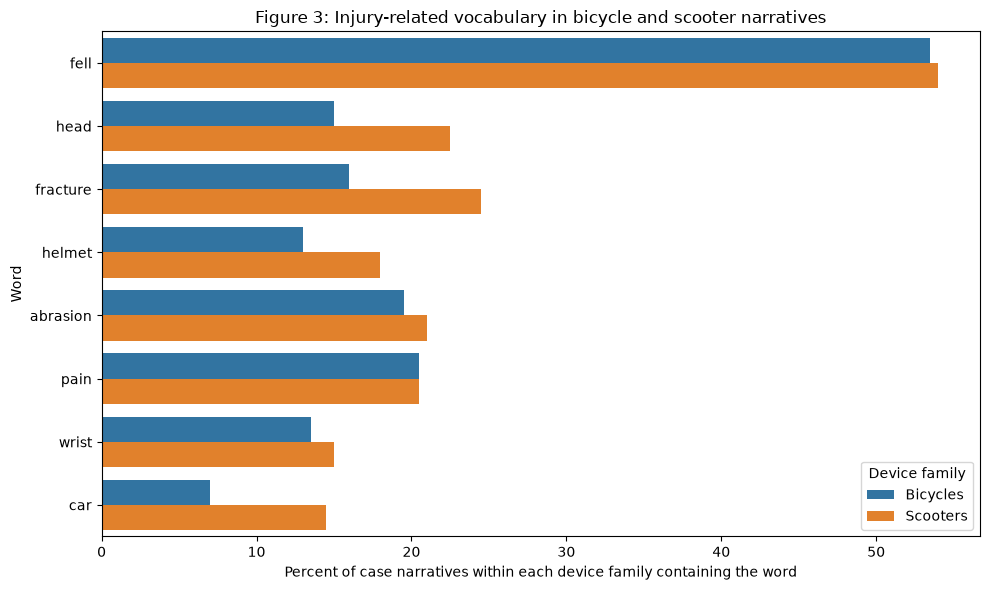

In [17]:
# Figure 3: Percent of narratives containing each word (one count per case, per word).
cpsc_words = ["fell", "head", "fracture", "helmet", "abrasion", "pain", "wrist", "car"]
cpsc_group_order = ["Bicycles", "Scooters"]
cpsc_chart_df = (cpsc_freq_df.set_index(["group", "word"])
                 .reindex(pd.MultiIndex.from_product([cpsc_group_order, cpsc_words], names=["group", "word"]),
                          fill_value=0).reset_index())
plt.figure(figsize=(10, 6))
sns.barplot(data=cpsc_chart_df, x="percent_documents", y="word", hue="group",
            hue_order=cpsc_group_order, order=cpsc_words)
plt.xlabel("Percent of case narratives within each device family containing the word")
plt.ylabel("Word")
plt.title("Figure 3: Injury-related vocabulary in bicycle and scooter narratives")
plt.legend(title="Device family")
plt.tight_layout()
plt.savefig(FIG_DIR / "neiss_word_percent.png", dpi=170)
plt.show()


**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

In Figure 3, "head" appears in 30 of 200 bicycle narratives (15.0%) and 45 of 200 scooter narratives (22.5%), while "fracture" appears in 32 bicycle narratives (16.0%) and 49 scooter narratives (24.5%). The term "fell" appears frequently in both groups: 107 of 200 bicycle cases (53.5%) and 108 of 200 scooter cases (54.0%). The chart therefore shows differences in reported vocabulary, but these are proportions among recorded cases, not rates of injury among users of the devices.


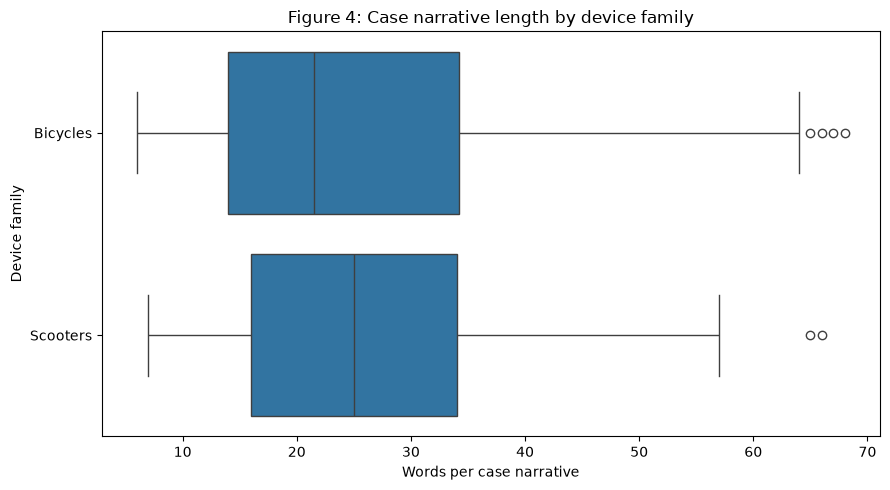

In [18]:
# Figure 4: Original narrative length distribution (whitespace-separated words).
plt.figure(figsize=(9, 5))
sns.boxplot(data=cpsc_selected_df, x="length_words", y="group", order=["Bicycles", "Scooters"],
            showfliers=True)
plt.xlabel("Words per case narrative")
plt.ylabel("Device family")
plt.title("Figure 4: Case narrative length by device family")
plt.tight_layout()
plt.savefig(FIG_DIR / "neiss_narrative_lengths.png", dpi=170)
plt.show()


**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Figure 4 adds information about text length that the word-frequency bars do not show. The median bicycle narrative is 21.5 words and the median scooter narrative is 25.0 words; the corresponding means are 25.95 and 26.53 words. The distributions therefore have similar average lengths, even though scooter narratives have a somewhat larger median. A longer record is not necessarily a more severe event, and differences may reflect reporting practices rather than the device itself.


### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [19]:
for group, word, expected in [("Bicycles", "helmet", 26), ("Scooters", "helmet", 36),
                              ("Bicycles", "head", 30), ("Scooters", "head", 45)]:
    rows = cpsc_selected_df.loc[cpsc_selected_df["group"] == group]
    count = rows["narrative"].str.lower().str.findall(r"[a-z']+").map(lambda v: word in v).sum()
    print(f"{group}: {word} = {count}/{len(rows)} ({100 * count / len(rows):.2f}%)")
    assert count == expected, "A plotted CPSC count does not match source records."
context_samples(cpsc_selected_df, "helmet", "narrative", "case_number")


Bicycles: helmet = 26/200 (13.00%)
Scooters: helmet = 36/200 (18.00%)
Bicycles: head = 30/200 (15.00%)
Scooters: head = 45/200 (22.50%)

Bicycles: 26 documents contain 'helmet'
  ID 250203292: ...IS KNEES. SCRAPED HIS R KNEE BUT THE L IS SWOLLEN. WAS WEARING A HELMET, DID NOT HIT HIS HEAD. DX: CLOSED FX OF L KNEE, SUPERFICIAL ABRASION TO R KNEE...
  ID 250214665: ... ON R SIDE, FACE MADE CONTACT WITH THE STREET. WAS NOT WEARING A HELMET. HE ATTEMPTED TO TURN L ONTO THE SIDEWALK FROM THE STREET, BUT THE FRONT WHEEL STALLED ON THE ...

Scooters: 36 documents contain 'helmet'
  ID 250153926: ...HEN HE FELL OFF STRIKING THE BACK OF HIS HEAD, WAS NOT WEARING A HELMET DX: CONCUSSION...
  ID 250184721: ...R AT 20MPH AND SHE FELL OFF STRIKING HER FACE, WAS NOT WEARING A HELMET DX: CONCUSSION, DENTAL INJURY...


**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

I independently checked the Figure 3 numerator and denominator for "helmet" (26 of 200 bicycle cases = 13.0%; 36 of 200 scooter cases = 18.0%) and "head" (30 of 200 bicycle cases = 15.0%; 45 of 200 scooter cases = 22.5%). Both agreed with the chart calculations. Looking at individual records containing "helmet" showed both "wearing a helmet" and "no helmet" uses. Thus, counting the term does not measure actual helmet use. The text excerpts also show clinical abbreviations that make some descriptions less straightforward. The counts needed no correction, but the interpretation had to acknowledge negation and shorthand.


### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

My research question asked whether injury-related vocabulary and narrative length differ between sampled bicycle and scooter emergency-department reports. Figure 3 shows that "head" is documented in 15.0% of bicycle narratives and 22.5% of scooter narratives, while "fell" is common in both (53.5% versus 54.0%). Figure 4 shows comparable narrative lengths, with median lengths of 21.5 words for bicycle cases and 25.0 for scooter cases. The prediction that both groups mention falls is supported, and some vocabulary differs. These patterns describe wording among the 400 sampled ED case records and cannot establish a relative risk of injury between bicycles and scooters.


### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

First, CPSC NEISS represents sampled emergency-department case records, not the total number of riders or trips. Without exposure denominators, the observed word percentages cannot demonstrate that one device is more dangerous or causes a particular injury. Second, clinical descriptions use abbreviations and wording varies by reporter; a term such as "helmet" may occur in statements that describe wearing or not wearing one. Figure 3 is precise about record-level vocabulary percentages but cannot reliably determine behavior or causation. Figure 4 shows the spread of narrative length but cannot determine medical seriousness or the real-world frequency of incidents.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Yes. I used an AI assistant to help draft the notebook code and check the analysis against the actual course CSV files. I verified source-record counts and the grouped percentages, including "great" in 67/160 high-rated reviews versus 24/160 low-rated reviews and "helmet" in 26/200 bicycle cases versus 36/200 scooter cases. I accepted the document-percentage approach because the denominators make group comparisons clear. I rejected any interpretation that a single word automatically proves sentiment or that case-narrative word frequency measures injury risk. I retained original texts, used fixed sampling, and documented the limitations.


## Submission checklist

- Include two distinct text datasets and document their sources, feature definitions, collection context, and access dates.
- Review the datasets and displayed language for work appropriateness; document any screening and its effects.
- Ask one research question per dataset and complete all six steps for each question.
- Complete both feature tables and every written response.
- Include four finished figures: two different chart types per question, with at least one numerical comparison per pair.
- Explain text preparation, stopwords, filtering, missing or blank text, duplicates, group sizes, and row counts.
- Define what is counted and the denominator of every percentage.
- Check two plotted values and original text context for each investigation.
- Restate each question in its conclusion and cite evidence from both figures.
- Identify two limitations per investigation and compare what the displays reveal or obscure.
- Include your data files and any preparation code using relative paths. Complete the AI-use reflection, restart the kernel, and run cells in order before submitting.
